# AnaeCare — 3-Class (Multinomial) Logistic Regression — Concat vs Self-Attention Fusion, 20 Epochs

**Converted from the continuous Hemoglobin-regression notebook back to classification — but 3-way, not binary.**

Instead of collapsing `Leve` (Mild) + `Moderada` (Moderate) into a single "Anemic" class (the original
binary `Anemia Predict` setup), this notebook predicts all **3 clinical severity classes directly**:
`Normal` / `Leve` / `Moderada`. This is **multinomial logistic regression**: the model's final layer is
a linear layer with **3 output logits**, trained with **softmax + cross-entropy** — the direct
generalization of binary logistic regression (1 logit + sigmoid + BCE) to more than 2 classes.

Key changes from the Hemoglobin-regression notebook (see markdown notes in each step for details):
- Target is once again a **class label**, but re-derived from `metadata.csv`'s `Normal`/`Leve`/`Moderado`
  one-hot columns (the verified-correct source — see Step 4), not the row-shifted `Class` column in
  `Dataset2.csv` and not the binary `Anemia Predict` column either.
- Labels are integer-encoded `Normal=0, Leve=1, Moderada=2` (`CLASS_TO_IDX` / `IDX_TO_CLASS` below).
- Loss: `MSELoss` -> `nn.CrossEntropyLoss(weight=...)`, with **inverse-frequency class weights** to
  handle the imbalance between Normal (~61%), Leve (~22%), and Moderada (~8%) — cross-entropy's
  multi-class analogue of the binary notebook's imbalance-weighted BCE.
- Final layer: `Linear(hidden, 1)` (raw Hb) -> `Linear(hidden, 3)` (one logit per class, softmax
  applied only at evaluation time to get probabilities — `CrossEntropyLoss` expects raw logits).
- Metrics: MAE/MSE/RMSE/R²/Pearson -> **Accuracy, macro-F1, macro-Precision, macro-Recall,
  macro-average one-vs-rest ROC-AUC, and a 3×3 confusion matrix** — the natural multi-class
  generalization of the original binary-classification metric set.
- Best-checkpoint selection: lowest val MAE -> **highest val macro-F1** (macro-F1 gives Leve/Moderada
  equal weight to Normal instead of letting the majority class dominate, same spirit as the original
  binary notebook favoring AUC-ROC over raw accuracy).
- Physiologically-impossible `Hemoglobina` outlier rows (123.0, 140.0 g/dL) are still dropped, since
  they're data-entry errors that indicate the corresponding metadata rows aren't trustworthy — this is
  independent of whether the target is Hb itself or the derived class.
- Backbone, fusion modules (`ConcatFusion` / `SelfAttentionFusion`), frame sampling (32 yemas / 16
  palmas), temporal pooling, augmentation/normalization, optimizer (Adam, lr=1e-4), batch size,
  epochs (20), and the train/validation/test **Split column** are all preserved unchanged, for a fair,
  consistent experiment against both prior notebooks (binary baseline and Hb regression).

## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.

In [6]:
import os
import json
import random
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                              precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize

random.seed(42); np.random.seed(42); torch.manual_seed(42)

# --- GPU setup (Kaggle "GPU T4 x2" = two physical T4s visible to this container) ---
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_MULTI_GPU = N_GPUS > 1   # quick_run() wraps the model in nn.DataParallel when True

print("Using device:", DEVICE)
if N_GPUS > 0:
    for i in range(N_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"USE_MULTI_GPU = {USE_MULTI_GPU}  ({N_GPUS} GPU(s) visible)")
if N_GPUS == 0:
    print("WARNING: no GPU visible - set Accelerator -> GPU T4 x2 in the notebook settings panel and restart.")


Using device: cuda
  GPU 0: Tesla T4
  GPU 1: Tesla T4
USE_MULTI_GPU = True  (2 GPU(s) visible)


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.

In [7]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")


input/
  datasets/
    shimu080/
      unas-palmas-yemas/
      metadata/
        metadata.csv
      dataset2/
        Dataset2.csv


## Step 2 — Config: Paths & Settings (manual paths, with auto-detect fallback)

**Fill in `MANUAL_PATHS` below using what Step 1.5 printed** — that's the
real, verified folder tree, so there's no guessing involved. Paste each path
in as a plain string (right up to the folder that directly contains the
`Leve` / `Moderada` / `Normal` class folders, or the CSV file itself for
`csv`). Leave any entry as `None` to fall back to auto-detection for just
that one item — but manual is the reliable option, use it if auto-detect has
failed before.

`RESULTS_DIR` lives under `/kaggle/working/` — the only writable location on
Kaggle (`/kaggle/input/` is strictly read-only).

In [8]:
# --- Manual path overrides ---
# Copy the exact paths from the Step 1.5 output above. Example, if Step 1.5 printed:
#   yemas_frames/
#     yemas_frames/
#       Leve/
#       Moderada/
#       Normal/
# then the path you want is "/kaggle/input/yemas_frames/yemas_frames" (the
# folder that directly CONTAINS Leve/Moderada/Normal, not the folder above it).
MANUAL_PATHS = {
    "csv":      "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",                     # <-- EDIT: exact path to Dataset2.csv (Split, YEMAS/PALMAS/UNAS Path columns)
    "metadata": "/kaggle/input/datasets/shimu080/metadata/metadata.csv",                     # <-- EDIT: exact path to metadata.csv (source of true Class one-hot columns)
    "yemas":    "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",                 # <-- EDIT
    "palmas":   "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",            # <-- EDIT
    "unas":     "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",             # <-- EDIT
}

KAGGLE_INPUT_ROOT = "/kaggle/input"
RESULTS_DIR_ROOT = "/kaggle/working"
_available_inputs = sorted(os.listdir(KAGGLE_INPUT_ROOT)) if os.path.isdir(KAGGLE_INPUT_ROOT) else []

def find_input_dataset(*keywords):
    """Auto-detect fallback: first folder directly under /kaggle/input whose
    name contains any of the given keywords. Only used when the matching
    MANUAL_PATHS entry above is None."""
    for entry in _available_inputs:
        full = os.path.join(KAGGLE_INPUT_ROOT, entry)
        if os.path.isdir(full) and any(k in entry.lower() for k in keywords):
            return full
    return None

def descend_if_nested(base, *keywords):
    if base is None or not os.path.isdir(base):
        return base
    for child in sorted(os.listdir(base)):
        child_path = os.path.join(base, child)
        if os.path.isdir(child_path) and any(k in child.lower() for k in keywords):
            if any(os.path.isdir(os.path.join(child_path, g)) for g in os.listdir(child_path)):
                return child_path
    return base

def find_csv_in(base):
    if base is None or not os.path.isdir(base):
        return None
    for f in sorted(os.listdir(base)):
        if f.lower().endswith(".csv"):
            return os.path.join(base, f)
    return None

# Manual path wins if set; otherwise fall back to auto-detection.
SPLIT_CSV_PATH = MANUAL_PATHS["csv"] or find_csv_in(find_input_dataset("dataset2", "dataset"))
METADATA_CSV_PATH = MANUAL_PATHS["metadata"] or SPLIT_CSV_PATH
YEMAS_DIR  = MANUAL_PATHS["yemas"]  or descend_if_nested(find_input_dataset("yemas"), "yemas")
PALMAS_DIR = MANUAL_PATHS["palmas"] or descend_if_nested(find_input_dataset("palmas", "palma"), "palmas", "palma")
UNAS_DIR   = MANUAL_PATHS["unas"]   or descend_if_nested(find_input_dataset("unas"), "unas")
FALLBACK_METADATA_CSV = SPLIT_CSV_PATH  # same source on Kaggle, kept for Step 4 compatibility

# Dedicated results folder in the writable Kaggle output area.
STAMP_RESULTS_BY_DATE = True
_run_date = datetime.now().strftime("%Y-%m-%d")
RESULTS_DIR = os.path.join(RESULTS_DIR_ROOT, "AnaeCare_results", "quick_fusion_test")
if STAMP_RESULTS_BY_DATE:
    RESULTS_DIR = os.path.join(RESULTS_DIR, _run_date)
os.makedirs(RESULTS_DIR, exist_ok=True)

EXPECTED_FRAME_COUNTS = {"yemas": 32, "palmas": 16}  # frames SAMPLED from each subject's extracted-frame folder
FRAME_IMAGE_EXTS = (".jpg", ".jpeg", ".png")          # extracted yemas/palmas frame files
IMAGE_EXTS = (".jpg", ".jpeg", ".png")                # single cropped unas nail image

# Folder-name template for each subject's extracted frames, relative to
# <modality_dir>/<Class>/ . Default assumes .../yemas_frames/<Class>/<ID>/frame_0001.jpg etc.
# Edit if your frames sit in a differently-named subfolder, e.g. "{id}_frames".
FRAME_FOLDER_TEMPLATE = "{id}"

# --- Multi-class label setup ---
CLASS_TO_IDX = {"Normal": 0, "Leve": 1, "Moderada": 2}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASS_TO_IDX)

# --- Run settings ---
SUBSET_SIZE = None     # None = use the full split file; set a number for a faster partial run
QUICK_EPOCHS = 20
BATCH_SIZE = 16 if USE_MULTI_GPU else 8   # bumped for 2x T4 so both GPUs stay fed
TEMPORAL_POOLING = "bilstm"   # "mean" or "bilstm"

print("SPLIT_CSV_PATH:", SPLIT_CSV_PATH or "NOT FOUND")
print("METADATA_CSV_PATH:", METADATA_CSV_PATH or "NOT FOUND")
print("YEMAS_DIR     :", YEMAS_DIR or "NOT FOUND")
print("PALMAS_DIR    :", PALMAS_DIR or "NOT FOUND")
print("UNAS_DIR      :", UNAS_DIR or "NOT FOUND")
print("RESULTS_DIR   :", RESULTS_DIR, "(writable Kaggle output area)")
print("CLASS_TO_IDX  :", CLASS_TO_IDX)
print(f"SUBSET_SIZE={SUBSET_SIZE}  QUICK_EPOCHS={QUICK_EPOCHS}  BATCH_SIZE={BATCH_SIZE}  TEMPORAL_POOLING={TEMPORAL_POOLING}")
if not (SPLIT_CSV_PATH and YEMAS_DIR and PALMAS_DIR and UNAS_DIR):
    print("\nSome paths above are NOT FOUND. Check the MANUAL_PATHS dict against the "
          "Step 1.5 output and fix the ones that don't match.")


SPLIT_CSV_PATH: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
METADATA_CSV_PATH: /kaggle/input/datasets/shimu080/metadata/metadata.csv
YEMAS_DIR     : /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS_DIR    : /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
UNAS_DIR      : /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
RESULTS_DIR   : /kaggle/working/AnaeCare_results/quick_fusion_test/2026-10-22 (writable Kaggle output area)
CLASS_TO_IDX  : {'Normal': 0, 'Leve': 1, 'Moderada': 2}
SUBSET_SIZE=None  QUICK_EPOCHS=20  BATCH_SIZE=16  TEMPORAL_POOLING=bilstm


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.

In [9]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)


YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Leve', 'Moderada', 'Normal']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load Split File + Metadata (true Class, integer-encoded label)

Same data-quality fix as the regression notebook: `Dataset2.csv`'s own `Class` column was found to
be **row-shifted (misaligned) for IDs 058-227** (~170 subjects) during verification — using it
directly would send those subjects' frame-loading code to the wrong class subfolder. So `Class` is
re-derived here from `metadata.csv`'s `Normal`/`Leve`/`Moderado` one-hot columns (verified ground
truth) instead, exactly as in the regression notebook.

**Classification-specific step:** the string `Class` (`Normal`/`Leve`/`Moderada`) is converted to an
integer label `y = CLASS_TO_IDX[Class]` (`0`/`1`/`2`) for `CrossEntropyLoss`, and class **inverse-
frequency weights** are computed from the training-set label distribution (set later, once `train_df`
exists in Step 5) to counteract the ~61% / 22% / 8% class imbalance.

The **`Split` column from `Dataset2.csv` is preserved unchanged** — it was verified to be
patient-ID-disjoint across train/validation/test and is not affected by the `Class` bug (only the
`Class` values in that one file were shifted, not `ID`/`Split`/path columns).

In [10]:
if os.path.isfile(SPLIT_CSV_PATH):
    metadata_source = SPLIT_CSV_PATH
elif os.path.isfile(FALLBACK_METADATA_CSV):
    metadata_source = FALLBACK_METADATA_CSV
    print(f"SPLIT_CSV_PATH not found - falling back to {FALLBACK_METADATA_CSV}")
else:
    raise FileNotFoundError(
        f"Could not find a metadata/split file at either:\n  {SPLIT_CSV_PATH}\n  {FALLBACK_METADATA_CSV}\n"
        f"Attach the dataset containing your split CSV as a Kaggle Input, or fix SPLIT_CSV_PATH in Step 2."
    )
if not os.path.isfile(METADATA_CSV_PATH):
    raise FileNotFoundError(
        f"Could not find metadata.csv (source of the true Class one-hot columns) at:\n  {METADATA_CSV_PATH}\n"
        f"Fix MANUAL_PATHS['metadata'] in Step 2."
    )

print("Using split file:", metadata_source)
print("Using metadata file (true Class one-hot columns):", METADATA_CSV_PATH)

split_df = pd.read_csv(metadata_source)
split_df = split_df.dropna(subset=["ID"]).copy()
split_df["ID"] = split_df["ID"].astype(str).str.strip()
assert "Split" in split_df.columns, "Split column missing from Dataset2.csv - cannot preserve the existing split."
split_df["Split"] = split_df["Split"].astype(str).str.strip()
# NOTE: Dataset2.csv's own "Class" / "Anemia Predict" columns are intentionally NOT used below -
# "Class" was found to be row-shifted/misaligned for IDs 058-227 during verification.
split_df = split_df[["ID", "Split"]]

meta_df = pd.read_csv(METADATA_CSV_PATH)
meta_df["ID"] = meta_df["ID"].astype(str).str.strip()
required_meta_cols = ["ID", "Normal", "Leve", "Moderado", "Hemoglobina"]
missing_meta_cols = [c for c in required_meta_cols if c not in meta_df.columns]
assert not missing_meta_cols, f"metadata.csv is missing required columns: {missing_meta_cols}"

# Re-derive Class from the one-hot columns (ground truth), instead of trusting any pre-existing
# Class column from Dataset2.csv.
def _derive_class(row):
    if row["Normal"] == 1:
        return "Normal"
    if row["Leve"] == 1:
        return "Leve"
    if row["Moderado"] == 1:
        return "Moderada"
    return None

meta_df["Class"] = meta_df.apply(_derive_class, axis=1)
assert meta_df["Class"].notna().all(), "Some metadata rows have no Normal/Leve/Moderado flag set - cannot derive Class."

# Drop physiologically-impossible Hemoglobina values (data-entry errors) - these rows are unreliable
# regardless of target, so they're dropped rather than silently corrected/guessed.
HB_MIN_PLAUSIBLE, HB_MAX_PLAUSIBLE = 3.0, 20.0
outlier_mask = (meta_df["Hemoglobina"] < HB_MIN_PLAUSIBLE) | (meta_df["Hemoglobina"] > HB_MAX_PLAUSIBLE)
n_outliers = int(outlier_mask.sum())
if n_outliers:
    print(f"Dropping {n_outliers} subject(s) with implausible Hemoglobina values "
          f"(outside [{HB_MIN_PLAUSIBLE}, {HB_MAX_PLAUSIBLE}] g/dL):")
    print(meta_df.loc[outlier_mask, ["ID", "Hemoglobina"]].to_string(index=False))
meta_df = meta_df.loc[~outlier_mask].reset_index(drop=True)

# Integer-encode the label for CrossEntropyLoss.
meta_df["Label"] = meta_df["Class"].map(CLASS_TO_IDX)
assert meta_df["Label"].notna().all(), "Some Class values did not map via CLASS_TO_IDX - check spelling/casing."
meta_df["Label"] = meta_df["Label"].astype(int)

# Merge: keep the ORIGINAL Split assignment (from Dataset2.csv), attach the corrected Class + Label.
metadata_df = split_df.merge(meta_df[["ID", "Class", "Label"]], on="ID", how="inner")
n_dropped_no_meta = len(split_df) - len(metadata_df)
if n_dropped_no_meta:
    print(f"NOTE: {n_dropped_no_meta} subject(s) in the split file had no matching metadata row "
          f"(dropped due to outlier removal above, or ID not present in metadata.csv).")

has_split_col = True
print(f"\n{len(metadata_df)} subjects with a valid Split + Class label.")
print(metadata_df["Split"].value_counts())
print("\nClass distribution:")
print(metadata_df["Class"].value_counts())


Using split file: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
Using metadata file (true Class one-hot columns): /kaggle/input/datasets/shimu080/metadata/metadata.csv
Dropping 2 subject(s) with implausible Hemoglobina values (outside [3.0, 20.0] g/dL):
   ID  Hemoglobina
ID645        123.0
ID843        140.0
NOTE: 2 subject(s) in the split file had no matching metadata row (dropped due to outlier removal above, or ID not present in metadata.csv).

907 subjects with a valid Split + Class label.
Split
train         634
validation    137
test          136
Name: count, dtype: int64

Class distribution:
Class
Normal      621
Leve        211
Moderada     75
Name: count, dtype: int64


## Step 5 — Existence Check + Build Train / Validation / Test

Unchanged logic (existence check per subject, patient-level disjoint split), except:
- Stratification (only used as a fallback if `Split` were missing, which it never is here) is on the
  `Class` label directly, since it's categorical again (was binned `Hemoglobina` in the regression
  notebook).
- The `Split` column loaded in Step 4 is used directly — **no new split is created.**
- **New:** once `train_df` exists, inverse-frequency **class weights** are computed from its label
  distribution and stored in `CLASS_WEIGHTS` (a tensor of length 3), passed to
  `nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)` in Step 8 so the ~61/22/8% imbalance doesn't make the
  model just predict "Normal" for everyone.

In [11]:
def subject_frame_folder(modality_dir, subj_class, subj_id):
    """Path to a subject's extracted-frame folder, e.g. dataset/yemas/<Class>/<ID>/."""
    folder_name = FRAME_FOLDER_TEMPLATE.format(id=subj_id)
    return os.path.join(modality_dir, subj_class, folder_name)

def list_frame_files(folder):
    """All extracted frame image paths in a subject's folder, sorted by filename."""
    if not os.path.isdir(folder):
        return []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(FRAME_IMAGE_EXTS))
    return [os.path.join(folder, f) for f in files]

def find_subject_file(modality_dir, subj_class, subj_id, exts):
    for ext in exts:
        p = os.path.join(modality_dir, subj_class, subj_id + ext)
        if os.path.isfile(p):
            return p
    return None

def subject_exists(subj_id, subj_class):
    y = len(list_frame_files(subject_frame_folder(YEMAS_DIR, subj_class, subj_id))) > 0
    p = len(list_frame_files(subject_frame_folder(PALMAS_DIR, subj_class, subj_id))) > 0
    u = find_subject_file(UNAS_DIR, subj_class, subj_id, IMAGE_EXTS) is not None
    return y and p and u

tqdm.pandas(desc="Checking files exist")
metadata_df["exists_all_3"] = metadata_df.progress_apply(
    lambda r: subject_exists(r["ID"], r["Class"]), axis=1
)
usable_df = metadata_df[metadata_df["exists_all_3"]].reset_index(drop=True)
print(f"\n{len(usable_df)} / {len(metadata_df)} subjects have all 3 modality inputs on disk.")

if len(usable_df) == 0:
    sample_row = metadata_df.iloc[0]
    example_path = subject_frame_folder(YEMAS_DIR, sample_row["Class"], sample_row["ID"])
    raise RuntimeError(
        f"No subjects passed the existence check. Example frame folder tried:\n  {example_path}\n"
        f"Check DATASET_DIR / folder names in Steps 2-3, and confirm your extracted frames sit at "
        f"dataset/<modality>/<Class>/<ID>/*.jpg (edit FRAME_FOLDER_TEMPLATE in Step 2 if your subfolder "
        f"naming differs). Class folders found there were printed above, compare against Class values in "
        f"your metadata (e.g. '{sample_row['Class']}')."
    )

if SUBSET_SIZE is not None and len(usable_df) > SUBSET_SIZE:
    from sklearn.model_selection import train_test_split as _tts
    usable_df, _ = _tts(usable_df, train_size=SUBSET_SIZE, stratify=usable_df["Class"], random_state=42)
    usable_df = usable_df.reset_index(drop=True)
    print(f"Subsampled down to {len(usable_df)} subjects (SUBSET_SIZE set).")

# has_split_col is always True here (Step 4 requires the Split column from Dataset2.csv to exist and
# raises otherwise) - the original random-split fallback branch is kept only for defensive
# completeness, now stratifying directly on the (again-categorical) Class label.
if has_split_col:
    train_df = usable_df[usable_df["Split"] == "train"].reset_index(drop=True)
    val_df   = usable_df[usable_df["Split"] == "validation"].reset_index(drop=True)
    test_df  = usable_df[usable_df["Split"] == "test"].reset_index(drop=True)
else:
    from sklearn.model_selection import train_test_split as _tts
    train_val_df, test_df = _tts(usable_df, test_size=0.15, stratify=usable_df["Class"], random_state=42)
    train_df, val_df = _tts(train_val_df, test_size=0.15/0.85, stratify=train_val_df["Class"], random_state=42)
    train_df, val_df, test_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

train_ids, val_ids, test_ids = set(train_df["ID"]), set(val_df["ID"]), set(test_df["ID"])
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
print("PASS: train/val/test are patient-level disjoint.")

print(f"\ntrain={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
print("train class counts:\n", train_df["Class"].value_counts())
print("val   class counts:\n", val_df["Class"].value_counts())
print("test  class counts:\n", test_df["Class"].value_counts())

# --- Class weights (inverse frequency, computed on TRAIN split only) for CrossEntropyLoss ---
_train_label_counts = train_df["Label"].value_counts().sort_index()  # index 0,1,2
_counts = np.array([_train_label_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=np.float64)
_inv_freq = _counts.sum() / (NUM_CLASSES * np.clip(_counts, 1, None))
CLASS_WEIGHTS = torch.tensor(_inv_freq, dtype=torch.float32)
print("\nTrain label counts (0=Normal,1=Leve,2=Moderada):", _counts.tolist())
print("CLASS_WEIGHTS (inverse frequency, for CrossEntropyLoss):", CLASS_WEIGHTS.tolist())


Checking files exist:   0%|          | 0/907 [00:00<?, ?it/s]


808 / 907 subjects have all 3 modality inputs on disk.
PASS: train/val/test are patient-level disjoint.

train=562  val=123  test=123
train class counts:
 Class
Normal      375
Leve        138
Moderada     49
Name: count, dtype: int64
val   class counts:
 Class
Normal      83
Leve        26
Moderada    14
Name: count, dtype: int64
test  class counts:
 Class
Normal      87
Leve        29
Moderada     7
Name: count, dtype: int64

Train label counts (0=Normal,1=Leve,2=Moderada): [375.0, 138.0, 49.0]
CLASS_WEIGHTS (inverse frequency, for CrossEntropyLoss): [0.4995555579662323, 1.3574879169464111, 3.823129177093506]


## Step 6 — Frame Sampling (Pre-Extracted) + Dataset Class

Unchanged: frame sampling, resize, ImageNet normalization, augmentation-free preprocessing exactly
as in the original notebooks (32 yemas frames, 16 palmas frames, evenly sampled from pre-extracted
folders, no on-the-fly video decoding).

**Classification change:** `__getitem__` now returns `label = torch.tensor(int(row["Label"]), dtype=torch.long)`
— a single class index in `{0, 1, 2}` — instead of a continuous Hb value or a 0/1 binary flag.

In [12]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
frame_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def sample_frame_paths(all_paths, n_frames):
    """Evenly sample n_frames image paths from an already-extracted frame
    folder. If fewer frames exist than n_frames, all are used (the caller
    pads the rest by repeating the last frame)."""
    if len(all_paths) == 0:
        return []
    if len(all_paths) <= n_frames:
        return all_paths
    indices = np.linspace(0, len(all_paths) - 1, n_frames).astype(int)
    return [all_paths[i] for i in indices]


class TriModalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def _load_frame_sequence(self, modality_dir, subj_class, subj_id, n_frames):
        folder = subject_frame_folder(modality_dir, subj_class, subj_id)
        all_paths = list_frame_files(folder)
        chosen = sample_frame_paths(all_paths, n_frames)
        imgs = [self.transform(Image.open(p).convert("RGB")) for p in chosen]
        while len(imgs) < n_frames:  # defensive pad, e.g. a subject with fewer frames than expected
            imgs.append(imgs[-1].clone() if imgs else torch.zeros(3, 224, 224))
        return torch.stack(imgs)

    def _load_image(self, modality_dir, subj_class, subj_id):
        img_path = find_subject_file(modality_dir, subj_class, subj_id, IMAGE_EXTS)
        if img_path:
            return self.transform(Image.open(img_path).convert("RGB"))
        return torch.zeros(3, 224, 224)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        subj_id, subj_class = row["ID"], row["Class"]
        yemas = self._load_frame_sequence(YEMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["yemas"])
        palmas = self._load_frame_sequence(PALMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["palmas"])
        unas = self._load_image(UNAS_DIR, subj_class, subj_id)
        # Multi-class label: 0=Normal, 1=Leve, 2=Moderada.
        label = torch.tensor(int(row["Label"]), dtype=torch.long)
        return yemas, palmas, unas, label

# Sanity check on one real subject before committing to a full run
_sample_row = train_df.iloc[0]
_sample_ds = TriModalDataset(train_df.iloc[[0]], frame_transform)
_y, _p, _u, _l = _sample_ds[0]
print(f"Sanity check on subject {_sample_row['ID']}: yemas={tuple(_y.shape)} "
      f"palmas={tuple(_p.shape)} unas={tuple(_u.shape)} label={_l.item()} ({IDX_TO_CLASS[_l.item()]})")
print("TriModalDataset ready (loading pre-extracted frames, no video decoding).")


Sanity check on subject ID001: yemas=(32, 3, 224, 224) palmas=(16, 3, 224, 224) unas=(3, 224, 224) label=0 (Normal)
TriModalDataset ready (loading pre-extracted frames, no video decoding).


## Step 7 — Model Building Blocks (Encoder, Temporal Pool, Fusion)

Unchanged from both prior notebooks. Two fusion modes side by side: `ConcatFusion` (baseline, no
learned interaction) and `SelfAttentionFusion` (proposed — 3 modality tokens attend to each other,
then mean-pooled).

In [13]:
class FrameEncoder(nn.Module):
    def __init__(self, embed_dim=256):
        super().__init__()
        backbone = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])
        self.proj = nn.Linear(512, embed_dim)

    def forward(self, x):
        return self.proj(self.backbone(x).flatten(1))


class TemporalPool(nn.Module):
    """mean: simple average over frames. bilstm: bidirectional LSTM, final
    hidden states concatenated + projected back to embed_dim."""
    def __init__(self, embed_dim=256, mode="mean", lstm_hidden=128):
        super().__init__()
        self.mode = mode
        if mode == "bilstm":
            self.lstm = nn.LSTM(embed_dim, lstm_hidden, batch_first=True, bidirectional=True)
            self.proj = nn.Linear(lstm_hidden * 2, embed_dim)

    def forward(self, x):
        if self.mode == "mean":
            return x.mean(dim=1)
        _, (h_n, _) = self.lstm(x)
        return self.proj(torch.cat([h_n[0], h_n[1]], dim=1))


class ConcatFusion(nn.Module):
    """Baseline: no learned cross-modal interaction."""
    def __init__(self, embed_dim=256):
        super().__init__()
        self.out_dim = embed_dim * 3

    def forward(self, v_yemas, v_palmas, v_unas):
        return torch.cat([v_yemas, v_palmas, v_unas], dim=1)


class SelfAttentionFusion(nn.Module):
    """Proposed: the 3 modality tokens attend to each other symmetrically."""
    def __init__(self, embed_dim=256, num_heads=4, dropout=0.3):
        super().__init__()
        self.modality_embed = nn.Parameter(torch.randn(3, embed_dim) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                            dim_feedforward=embed_dim * 2,
                                            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.out_dim = embed_dim

    def forward(self, v_yemas, v_palmas, v_unas):
        x = torch.stack([v_yemas, v_palmas, v_unas], dim=1) + self.modality_embed.unsqueeze(0)
        return self.encoder(x).mean(dim=1)

print("Model building blocks ready.")


Model building blocks ready.


## Step 8 — Full Model + Train/Eval Functions (Multinomial Logistic Regression Head + Metrics)

`AnaeCareModel`'s architecture (encoders, temporal pooling, fusion) is **unchanged**. What changes
is the classifier head and everything downstream of it:
- Final layer: `Linear(hidden, 1)` -> **`Linear(hidden, NUM_CLASSES)`** (3 raw logits, one per class —
  no activation applied here; `nn.CrossEntropyLoss` applies log-softmax internally, which is exactly
  the multinomial-logistic-regression setup: softmax generalizes binary logistic regression's sigmoid
  to >2 classes).
- `criterion`: `nn.MSELoss()` -> **`nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)`** — the multi-class
  generalization of the original notebook's imbalance-weighted `BCEWithLogitsLoss`.
- `evaluate()`: drops MAE/MSE/RMSE/R²/Pearson and computes **accuracy, macro-precision, macro-recall,
  macro-F1, macro one-vs-rest ROC-AUC**, and returns the raw predicted class indices, true labels, and
  softmax probabilities (needed later for ROC curves and the confusion matrix).
- Best-checkpoint selection: lowest validation MAE -> **highest validation macro-F1** — macro-F1
  weights Normal/Leve/Moderada equally, so the checkpoint isn't picked purely by how well it predicts
  the majority "Normal" class.

In [14]:
class AnaeCareModel(nn.Module):
    def __init__(self, fusion="concat", temporal_pooling="mean", embed_dim=256, dropout=0.3, num_classes=NUM_CLASSES):
        super().__init__()
        self.yemas_encoder = FrameEncoder(embed_dim)
        self.palmas_encoder = FrameEncoder(embed_dim)
        self.unas_encoder = FrameEncoder(embed_dim)
        self.yemas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.palmas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.fusion = ConcatFusion(embed_dim) if fusion == "concat" else SelfAttentionFusion(embed_dim, dropout=dropout)
        hidden = 128 if fusion == "concat" else 64
        # Multinomial logistic regression head: NUM_CLASSES raw logits, no activation here -
        # nn.CrossEntropyLoss applies log-softmax internally during training.
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion.out_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, num_classes)
        )

    def forward(self, yemas, palmas, unas):
        B, Ty, C, H, W = yemas.shape
        _, Tp, _, _, _ = palmas.shape
        y = self.yemas_encoder(yemas.reshape(B * Ty, C, H, W)).view(B, Ty, -1)
        p = self.palmas_encoder(palmas.reshape(B * Tp, C, H, W)).view(B, Tp, -1)
        v_yemas, v_palmas = self.yemas_pool(y), self.palmas_pool(p)
        v_unas = self.unas_encoder(unas)
        fused = self.fusion(v_yemas, v_palmas, v_unas)
        return self.classifier(fused)  # raw logits, shape (B, NUM_CLASSES)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0.0
    for yemas, palmas, unas, labels in tqdm(loader, desc="train", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(yemas, palmas, unas), labels)
        loss.backward(); optimizer.step()
        total += loss.item() * len(labels)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Multi-class classification metrics: accuracy, macro precision/recall/F1, macro one-vs-rest
    ROC-AUC, and the confusion matrix - replacing the regression metric set (MAE/MSE/RMSE/R2/Pearson)."""
    model.eval()
    total, probs_all, labels_all = 0.0, [], []
    for yemas, palmas, unas, labels in tqdm(loader, desc="eval", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        logits = model(yemas, palmas, unas)
        total += criterion(logits, labels).item() * len(labels)
        probs_all.append(F.softmax(logits, dim=1).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    probs, labels = np.concatenate(probs_all), np.concatenate(labels_all)
    preds = probs.argmax(axis=1)

    acc = accuracy_score(labels, preds)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, preds, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0
    )
    try:
        # One-vs-rest macro AUC; needs >=2 classes present with >=1 sample each in `labels`.
        y_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
        auc_macro = roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
    except ValueError:
        auc_macro = float("nan")  # e.g. a class missing entirely from this split

    cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))
    metrics = {
        "loss": total / len(loader.dataset),
        "accuracy": float(acc),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "auc_macro_ovr": float(auc_macro),
    }
    return metrics, preds, labels, probs, cm


def quick_run(fusion_name, temporal_pooling=TEMPORAL_POOLING, epochs=QUICK_EPOCHS):
    print(f"\n===== Run: fusion={fusion_name}  temporal_pooling={temporal_pooling}  epochs={epochs} =====")
    loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))
    train_loader = DataLoader(TriModalDataset(train_df, frame_transform), batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
    val_loader = DataLoader(TriModalDataset(val_df, frame_transform), batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(TriModalDataset(test_df, frame_transform), batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

    model = AnaeCareModel(fusion=fusion_name, temporal_pooling=temporal_pooling).to(DEVICE)
    if USE_MULTI_GPU:
        model = nn.DataParallel(model)   # splits each batch across the 2 T4s
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))  # multinomial logistic regression loss
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    history = []
    best_val_f1, best_state = -float("inf"), None  # highest val macro-F1 wins
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics, _, _, _, _ = evaluate(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss, **val_metrics})
        print(f"Epoch {epoch}/{epochs}  train_loss(CE)={train_loss:.4f}  val_loss(CE)={val_metrics['loss']:.4f}  "
              f"val_acc={val_metrics['accuracy']:.3f}  val_F1_macro={val_metrics['f1_macro']:.3f}  "
              f"val_AUC_macro={val_metrics['auc_macro_ovr']:.3f}")
        if val_metrics["f1_macro"] == val_metrics["f1_macro"] and val_metrics["f1_macro"] > best_val_f1:
            best_val_f1 = val_metrics["f1_macro"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    test_metrics, test_preds, test_labels, test_probs, test_cm = evaluate(model, test_loader, criterion)
    print("\nFinal TEST metrics (best val-F1_macro checkpoint):")
    for k, v in test_metrics.items():
        print(f"  {k}: {v:.4f}")
    print("Confusion matrix (rows=true, cols=pred, order=Normal/Leve/Moderada):")
    print(test_cm)

    return model, pd.DataFrame(history), test_metrics, test_preds, test_labels, test_probs, test_cm

print("Training/eval utilities ready (multinomial logistic regression).")


Training/eval utilities ready (multinomial logistic regression).


## Step 9 — Train: Concatenation Fusion (baseline), 20 Epochs

In [16]:
(concat_model, concat_history, concat_test_metrics,
 concat_test_preds, concat_test_labels, concat_test_probs, concat_test_cm) = quick_run("concat")

concat_history.to_csv(os.path.join(RESULTS_DIR, "concat_history.csv"), index=False)
with open(os.path.join(RESULTS_DIR, "concat_test_metrics.json"), "w") as f:
    json.dump(concat_test_metrics, f, indent=2)
np.savez(os.path.join(RESULTS_DIR, "concat_test_raw.npz"),
         preds=concat_test_preds, labels=concat_test_labels, probs=concat_test_probs, cm=concat_test_cm)
torch.save(concat_model.state_dict(), os.path.join(RESULTS_DIR, "concat_model.pt"))
concat_history



===== Run: fusion=concat  temporal_pooling=bilstm  epochs=20 =====


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/20  train_loss(CE)=1.0539  val_loss(CE)=1.0615  val_acc=0.618  val_F1_macro=0.327  val_AUC_macro=0.681


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (54 outputs left out)

Epoch 20/20  train_loss(CE)=0.0931  val_loss(CE)=1.7889  val_acc=0.463  val_F1_macro=0.382  val_AUC_macro=0.621


eval:   0%|          | 0/8 [00:00<?, ?it/s]


Final TEST metrics (best val-F1_macro checkpoint):
  loss: 0.9516
  accuracy: 0.5691
  precision_macro: 0.4510
  recall_macro: 0.4992
  f1_macro: 0.4388
  auc_macro_ovr: 0.7420
Confusion matrix (rows=true, cols=pred, order=Normal/Leve/Moderada):
[[54 17 16]
 [ 9 13  7]
 [ 1  3  3]]


,epoch,train_loss,loss,accuracy,precision_macro,recall_macro,f1_macro,auc_macro_ovr
0,1,1.053870,1.061515,0.617886,0.308502,0.349243,0.326740,0.681367
1,2,0.910301,0.914550,0.552846,0.489092,0.528289,0.488708,0.743510
2,3,0.700468,1.766947,0.650407,0.422892,0.378481,0.367785,0.658247
3,4,0.547857,1.126933,0.504065,0.465168,0.543713,0.386696,0.705873
4,5,0.557556,1.040980,0.487805,0.495476,0.555541,0.444586,0.711152
5,6,0.332608,2.146382,0.642276,0.486246,0.392074,0.399215,0.648781
6,7,0.185602,1.703505,0.585366,0.494980,0.407984,0.415828,0.680038
7,8,0.123540,1.748741,0.536585,0.457554,0.423474,0.429282,0.665906
8,9,0.152599,2.005953,0.552846,0.439484,0.385299,0.399733,0.613780
9,10,0.146613,2.361205,0.544715,0.379768,0.359305,0.355822,0.582394


## Step 10 — Train: Self-Attention Fusion (proposed), 20 Epochs

In [17]:
import gc

if 'concat_model' in globals():
    concat_model.to("cpu")
    del concat_model

gc.collect()
torch.cuda.empty_cache()

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        free_b, total_b = torch.cuda.mem_get_info(i)
        print(f"GPU {i}: {free_b / 1024**3:.2f} GiB free / {total_b / 1024**3:.2f} GiB total")

GPU 0: 12.79 GiB free / 14.56 GiB total
GPU 1: 13.88 GiB free / 14.56 GiB total


In [19]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
(selfattn_model, selfattn_history, selfattn_test_metrics,
 selfattn_test_preds, selfattn_test_labels, selfattn_test_probs, selfattn_test_cm) = quick_run("self_attention")

selfattn_history.to_csv(os.path.join(RESULTS_DIR, "self_attention_history.csv"), index=False)
with open(os.path.join(RESULTS_DIR, "self_attention_test_metrics.json"), "w") as f:
    json.dump(selfattn_test_metrics, f, indent=2)
np.savez(os.path.join(RESULTS_DIR, "self_attention_test_raw.npz"),
         preds=selfattn_test_preds, labels=selfattn_test_labels, probs=selfattn_test_probs, cm=selfattn_test_cm)
torch.save(selfattn_model.state_dict(), os.path.join(RESULTS_DIR, "self_attention_model.pt"))
selfattn_history



===== Run: fusion=self_attention  temporal_pooling=bilstm  epochs=20 =====


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/20  train_loss(CE)=1.0721  val_loss(CE)=1.0015  val_acc=0.537  val_F1_macro=0.406  val_AUC_macro=0.685


train:   0%|          | 0/36 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (54 outputs left out)

Epoch 20/20  train_loss(CE)=0.1297  val_loss(CE)=2.8002  val_acc=0.626  val_F1_macro=0.311  val_AUC_macro=0.573


eval:   0%|          | 0/8 [00:00<?, ?it/s]


Final TEST metrics (best val-F1_macro checkpoint):
  loss: 1.0069
  accuracy: 0.5691
  precision_macro: 0.4115
  recall_macro: 0.4269
  f1_macro: 0.4064
  auc_macro_ovr: 0.6974
Confusion matrix (rows=true, cols=pred, order=Normal/Leve/Moderada):
[[54 25  8]
 [ 9 15  5]
 [ 4  2  1]]


,epoch,train_loss,loss,accuracy,precision_macro,recall_macro,f1_macro,auc_macro_ovr
0,1,1.072099,1.001500,0.536585,0.412233,0.425659,0.406245,0.685239
1,2,0.969353,1.055528,0.544715,0.406757,0.368110,0.363582,0.698473
2,3,0.771643,1.072098,0.544715,0.441799,0.445099,0.431094,0.689476
3,4,0.576756,1.328584,0.487805,0.406880,0.388389,0.379355,0.644122
4,5,0.454755,1.831448,0.406504,0.441042,0.390066,0.341049,0.593462
5,6,0.412739,2.043142,0.317073,0.393756,0.343704,0.256965,0.604368
6,7,0.313731,1.514634,0.504065,0.402525,0.387616,0.385144,0.649100
7,8,0.371087,1.778834,0.585366,0.373803,0.363961,0.365266,0.602413
8,9,0.289098,1.728849,0.544715,0.386310,0.361490,0.367489,0.619948
9,10,0.234224,1.592528,0.569106,0.432690,0.430734,0.428954,0.628956


## Step 11 — Confusion Matrices + One-vs-Rest ROC Curves

Replaces the predicted-vs-actual scatter/residual-histogram cell (not meaningful for a categorical
output) with the standard multi-class diagnostics:
- **3×3 confusion matrices** (Normal / Leve / Moderada), one per fusion method.
- **One-vs-rest ROC curves**, one line per class plus the macro-average, one panel per fusion method
  — the multi-class generalization of a single binary ROC curve.

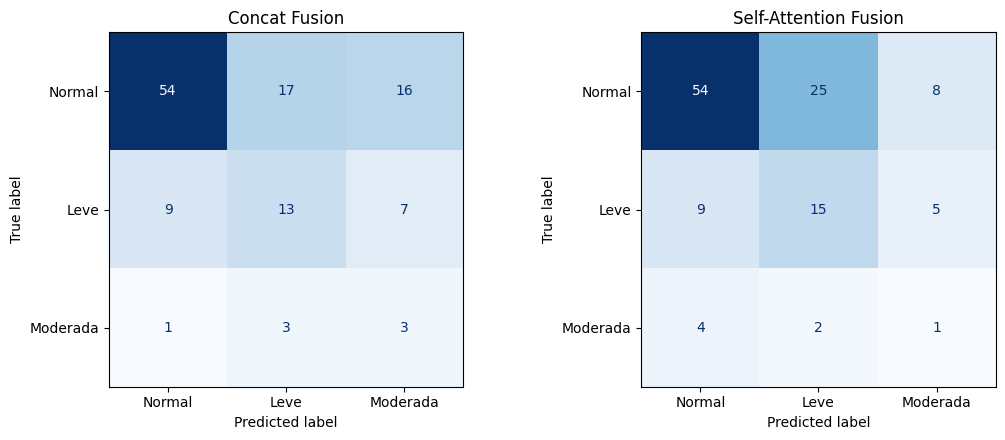

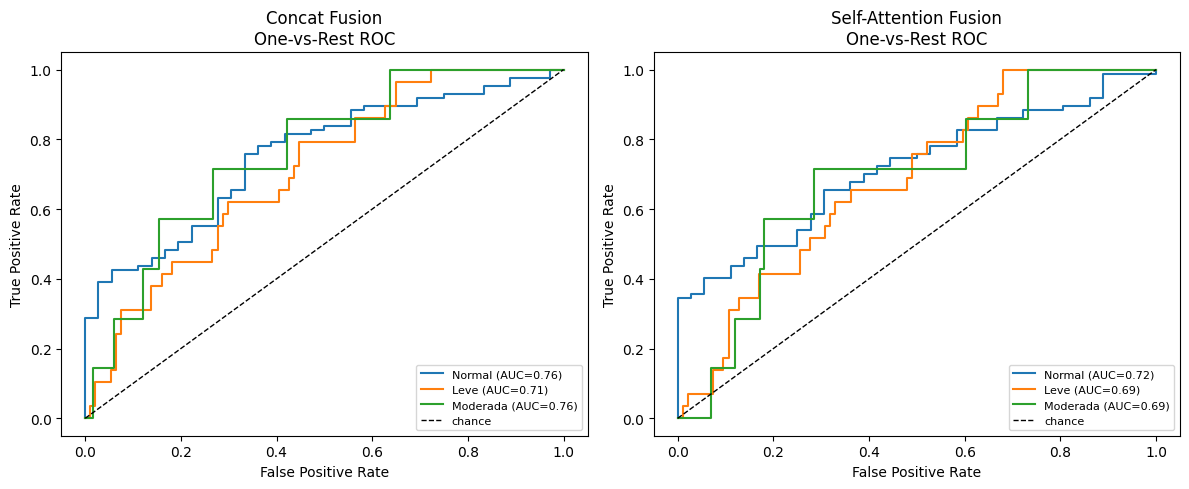

In [20]:
from sklearn.metrics import roc_curve, auc as sk_auc

CLASS_NAMES = [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)]

# --- Confusion matrices ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name, cm in [
    (axes[0], "Concat Fusion", concat_test_cm),
    (axes[1], "Self-Attention Fusion", selfattn_test_cm),
]:
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
cm_png = os.path.join(RESULTS_DIR, "confusion_matrices.png")
plt.savefig(cm_png, dpi=150, bbox_inches="tight")
plt.show()

# --- One-vs-rest ROC curves ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, labels, probs in [
    (axes[0], "Concat Fusion", concat_test_labels, concat_test_probs),
    (axes[1], "Self-Attention Fusion", selfattn_test_labels, selfattn_test_probs),
]:
    y_bin = label_binarize(labels, classes=list(range(NUM_CLASSES)))
    for c in range(NUM_CLASSES):
        if y_bin[:, c].sum() == 0:  # class absent from this split - can't draw a curve for it
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, c], probs[:, c])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC={sk_auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="chance")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name}\nOne-vs-Rest ROC")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
roc_png = os.path.join(RESULTS_DIR, "roc_curves_ovr.png")
plt.savefig(roc_png, dpi=150, bbox_inches="tight")
plt.show()


## Step 12 — Final Comparison Table (Classification Metrics)

        fusion  accuracy  precision_macro  recall_macro  f1_macro  auc_macro_ovr     loss
        concat  0.569106         0.451025      0.499179  0.438802       0.742039 0.951556
self_attention  0.569106         0.411514      0.426929  0.406357       0.697448 1.006913


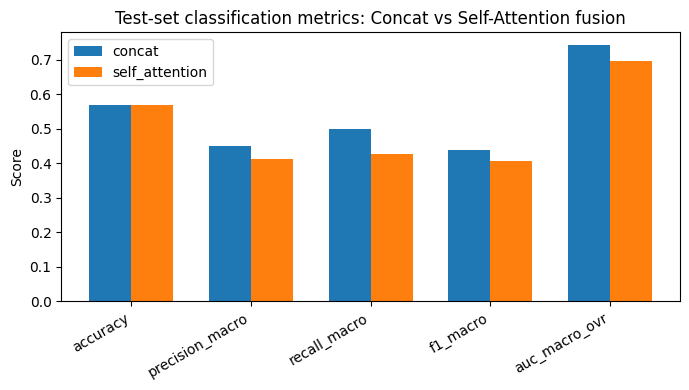


All outputs saved to the new results folder: /kaggle/working/AnaeCare_results/quick_fusion_test/2026-10-22
Used 562 train / 123 val / 123 test subjects, 20 epochs.


In [21]:
compare_df = pd.DataFrame([
    {"fusion": "concat", **concat_test_metrics},
    {"fusion": "self_attention", **selfattn_test_metrics},
])
cols = ["fusion", "accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr", "loss"]
print(compare_df[cols].to_string(index=False))

compare_csv = os.path.join(RESULTS_DIR, "quick_fusion_comparison.csv")
compare_df.to_csv(compare_csv, index=False)

fig, ax = plt.subplots(figsize=(7, 4))
metric_names = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro_ovr"]
x = np.arange(len(metric_names))
width = 0.35
ax.bar(x - width/2, compare_df.loc[compare_df["fusion"] == "concat", metric_names].values[0], width, label="concat")
ax.bar(x + width/2, compare_df.loc[compare_df["fusion"] == "self_attention", metric_names].values[0], width, label="self_attention")
ax.set_xticks(x); ax.set_xticklabels(metric_names, rotation=30, ha="right")
ax.set_ylabel("Score")
ax.set_title("Test-set classification metrics: Concat vs Self-Attention fusion")
ax.legend()
plt.tight_layout()
metrics_png = os.path.join(RESULTS_DIR, "quick_fusion_metrics_bar.png")
plt.savefig(metrics_png, dpi=150, bbox_inches="tight")
plt.show()

print("\nAll outputs saved to the new results folder:", RESULTS_DIR)
print(f"Used {len(train_df)} train / {len(val_df)} val / {len(test_df)} test subjects, {QUICK_EPOCHS} epochs.")


## Step 13 — Zip Everything & Get a Download Link

Bundles every file written to `RESULTS_DIR` this run — histories, test
metrics, confusion matrices, ROC curves, the comparison table/bar chart,
raw test predictions/probabilities/labels, and both trained models' weights
(`concat_model.pt`, `self_attention_model.pt`) — into a single `.zip` in
`/kaggle/working/`. Click the link below to download it directly, so the
results survive even after the session ends (Kaggle also keeps
`/kaggle/working/` as "Output" on the notebook version, but a manual
download right after the run is the safest bet).

In [23]:
import shutil
from IPython.display import FileLink, display

zip_base = os.path.join(RESULTS_DIR_ROOT, f"anaecare_results_{_run_date}")
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)

print("Files bundled into the zip:")
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        print(f"  {os.path.relpath(full, RESULTS_DIR)}  ({os.path.getsize(full) / 1024:.1f} KB)")

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"\nZip written to: {zip_path}  ({zip_size_mb:.1f} MB)")
print("Click below to download it (it's also visible under this notebook's Output tab):")
display(FileLink(os.path.relpath(zip_path, os.getcwd())))


Files bundled into the zip:
  concat_history.csv  (2.7 KB)
  concat_model.pt  (136754.5 KB)
  concat_test_metrics.json  (0.2 KB)
  concat_test_raw.npz  (4.4 KB)
  concat_training_vs_validation_loss.png  (174.9 KB)
  confusion_matrices.png  (35.5 KB)
  quick_fusion_comparison.csv  (0.3 KB)
  quick_fusion_metrics_bar.png  (49.9 KB)
  roc_curves_ovr.png  (84.6 KB)
  self_attention_history.csv  (2.8 KB)
  self_attention_model.pt  (138503.6 KB)
  self_attention_test_metrics.json  (0.2 KB)
  self_attention_test_raw.npz  (4.4 KB)

Zip written to: /kaggle/working/anaecare_results_2026-10-22.zip  (249.6 MB)
Click below to download it (it's also visible under this notebook's Output tab):


/kaggle/working/anaecare_results_2026-10-22.zip

# Epoch vs Training and Validation Loss (Cross-Entropy, multi-class) — example plot from a saved history CSV

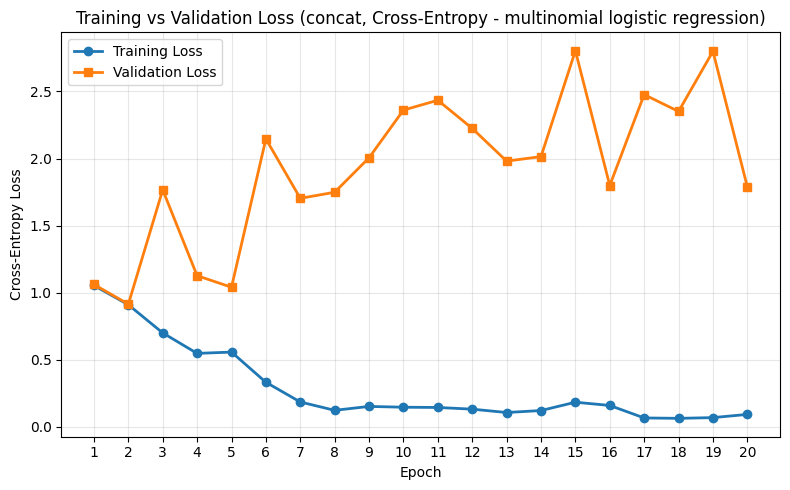

In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Read the history CSV from THIS session's run (Step 9), not the old 10-epoch reference file
df = pd.read_csv(os.path.join(RESULTS_DIR, "concat_history.csv"))

plt.figure(figsize=(8,5))
plt.plot(df["epoch"], df["train_loss"], marker="o", linewidth=2, label="Training Loss")
plt.plot(df["epoch"], df["loss"], marker="s", linewidth=2, label="Validation Loss")
plt.title("Training vs Validation Loss (concat, Cross-Entropy - multinomial logistic regression)")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(df["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "concat_training_vs_validation_loss.png"), dpi=300, bbox_inches="tight")
plt.show()